In [1]:
# ============================================================
# STEP 1: INSTALL CLIP AND CHECK GPU
# ============================================================

%pip install -q git+https://github.com/openai/CLIP.git ftfy regex tqdm scikit-learn seaborn

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable GPU: Runtime → Change runtime type → T4 GPU")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# ============================================================
# STEP 2: LOAD THE CLIP MODEL
# ============================================================

import clip

# Load pretrained CLIP and its image preprocessing function
model, preprocess = clip.load("ViT-B/32", device=device)

# Set the model to evaluation mode
model.eval()

print("CLIP model: ViT-B/32")
print("Device:", device)
print("Model loaded successfully.")

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 158MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP model: ViT-B/32
Device: cuda
Model loaded successfully.


In [3]:
# ============================================================
# STEP 3: LOAD CIFAR-10 AND SELECT 100 IMAGES PER CLASS
# ============================================================

import numpy as np
import pandas as pd
from torchvision.datasets import CIFAR10

# Load original images from the test set
dataset = CIFAR10(
    root="./data",
    train=False,
    download=True
)

class_names = dataset.classes
targets = np.array(dataset.targets)

# Reproducible, balanced sample: 100 images × 10 classes
SEED = 42
IMAGES_PER_CLASS = 100
rng = np.random.default_rng(SEED)

selected_indices = np.concatenate([
    rng.choice(
        np.flatnonzero(targets == class_id),
        size=IMAGES_PER_CLASS,
        replace=False
    )
    for class_id in range(len(class_names))
])

rng.shuffle(selected_indices)

images = [dataset[int(i)][0] for i in selected_indices]
labels = targets[selected_indices]

# Verify sample size, uniqueness, and class balance
assert len(images) == 1000
assert len(np.unique(selected_indices)) == 1000
assert np.all(np.bincount(labels, minlength=10) == IMAGES_PER_CLASS)

display(pd.DataFrame({
    "Class": class_names,
    "Selected images": np.bincount(labels, minlength=10)
}))

print(f"\nTotal selected images: {len(images)}")
print("Dataset split: test")
print("Random seed:", SEED)
print("STEP 3 completed successfully.")

100%|██████████| 170M/170M [20:40<00:00, 137kB/s]


,Class,Selected images
0,airplane,100
1,automobile,100
2,bird,100
3,cat,100
4,deer,100
5,dog,100
6,frog,100
7,horse,100
8,ship,100
9,truck,100



Total selected images: 1000
Dataset split: test
Random seed: 42
STEP 3 completed successfully.


In [4]:
# ============================================================
# STEP 4: DEFINE CAPTION, PREPROCESS IMAGES, EXTRACT EMBEDDINGS
# ============================================================

from tqdm.auto import tqdm
import torch.nn.functional as F

caption = "a photo of a dog."
BATCH_SIZE = 64

image_features_list = []

with torch.inference_mode():
    # Encode and normalize the caption
    caption_tokens = clip.tokenize([caption]).to(device)
    caption_features = model.encode_text(caption_tokens).float()
    caption_features = F.normalize(caption_features, dim=-1)

    # Preprocess, encode, and normalize images in batches
    for start in tqdm(
        range(0, len(images), BATCH_SIZE),
        desc="Encoding images"
    ):
        batch_images = images[start:start + BATCH_SIZE]

        batch = torch.stack([
            preprocess(image) for image in batch_images
        ]).to(device)

        features = model.encode_image(batch).float()
        features = F.normalize(features, dim=-1)

        image_features_list.append(features.cpu())

# Preserve the same order as images and labels
image_features = torch.cat(image_features_list, dim=0)
caption_features = caption_features.cpu()

# Verify embeddings
assert image_features.shape[0] == len(images)
assert torch.isfinite(image_features).all()
assert torch.allclose(
    image_features.norm(dim=-1),
    torch.ones(len(images)),
    atol=1e-5
)

print("\nCaption:", caption)
print("Image embeddings shape:", tuple(image_features.shape))
print("Caption embedding shape:", tuple(caption_features.shape))
print("Embeddings normalized successfully.")
print("STEP 4 completed successfully.")

Encoding images:   0%|          | 0/16 [00:00<?, ?it/s]


Caption: a photo of a dog.
Image embeddings shape: (1000, 512)
Caption embedding shape: (1, 512)
Embeddings normalized successfully.
STEP 4 completed successfully.


In [5]:
# ============================================================
# STEP 5: COMPUTE CAPTION–IMAGE SIMILARITY SCORES
# ============================================================

# Dot product of normalized embeddings = cosine similarity
similarity_scores = (
    image_features @ caption_features.T
).squeeze(1).numpy()

# Record the score for every selected image
similarity_df = pd.DataFrame({
    "Sample index": np.arange(len(images)),
    "CIFAR-10 test index": selected_indices,
    "Actual class": [class_names[int(label)] for label in labels],
    "Cosine similarity": similarity_scores
})

# Summarize similarity by actual class
class_similarity_summary = (
    similarity_df.groupby("Actual class")["Cosine similarity"]
    .agg(["count", "mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

print("Caption:", caption)
print("\nSimilarity summary by class:")
display(class_similarity_summary.round(4))

print("\nTop 10 matching images:")
display(
    similarity_df.sort_values(
        "Cosine similarity", ascending=False
    ).head(10).round(4)
)

assert len(similarity_scores) == 1000
assert np.isfinite(similarity_scores).all()

print("\nSTEP 5 completed successfully.")

Caption: a photo of a dog.

Similarity summary by class:


,count,mean,std,min,max
Actual class,,,,,
dog,100,0.2599,0.0108,0.2238,0.2821
cat,100,0.2371,0.0119,0.2093,0.2751
deer,100,0.2315,0.0144,0.1859,0.2640
frog,100,0.2265,0.0121,0.1937,0.2527
bird,100,0.2222,0.0133,0.1986,0.2662
horse,100,0.2168,0.0148,0.1699,0.2598
airplane,100,0.1998,0.0141,0.1544,0.2355
automobile,100,0.1971,0.0106,0.1699,0.2206
ship,100,0.1914,0.0141,0.1599,0.2280



Top 10 matching images:


,Sample index,CIFAR-10 test index,Actual class,Cosine similarity
669,669,3323,dog,0.2821
843,843,2989,dog,0.2776
104,104,1620,dog,0.2772
508,508,8289,dog,0.2770
77,77,7827,cat,0.2751
106,106,1329,dog,0.2747
895,895,3334,dog,0.2739
459,459,437,dog,0.2731
814,814,7244,dog,0.2720
607,607,640,dog,0.2715



STEP 5 completed successfully.


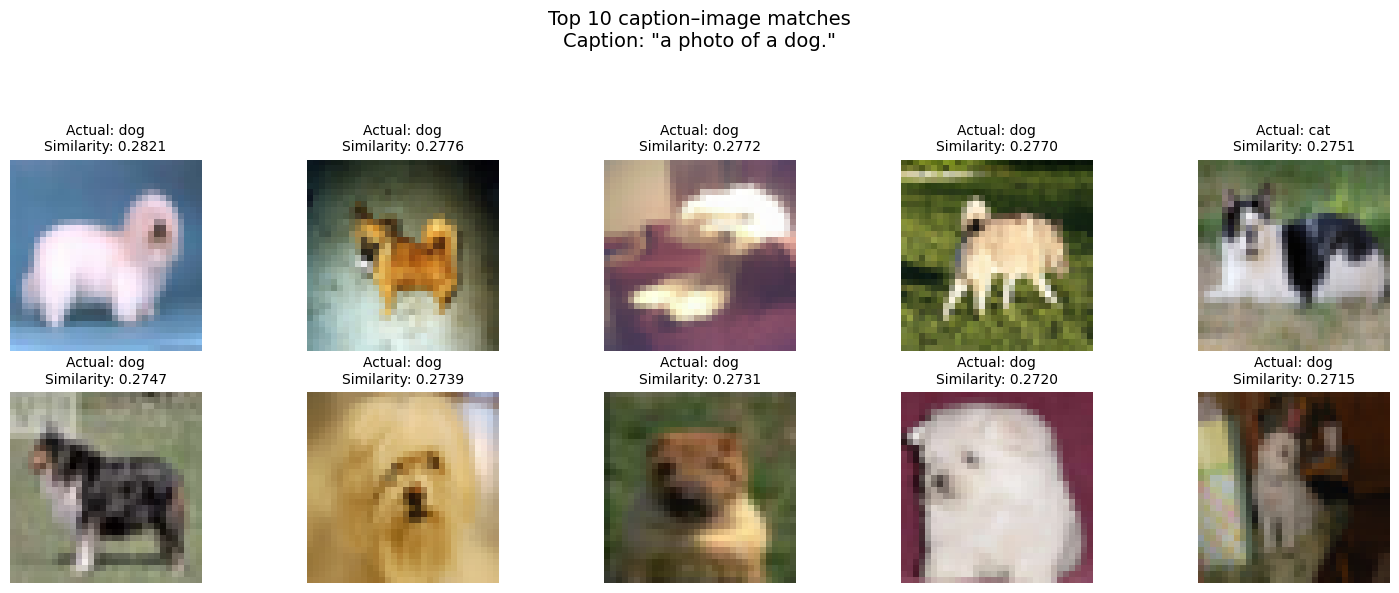

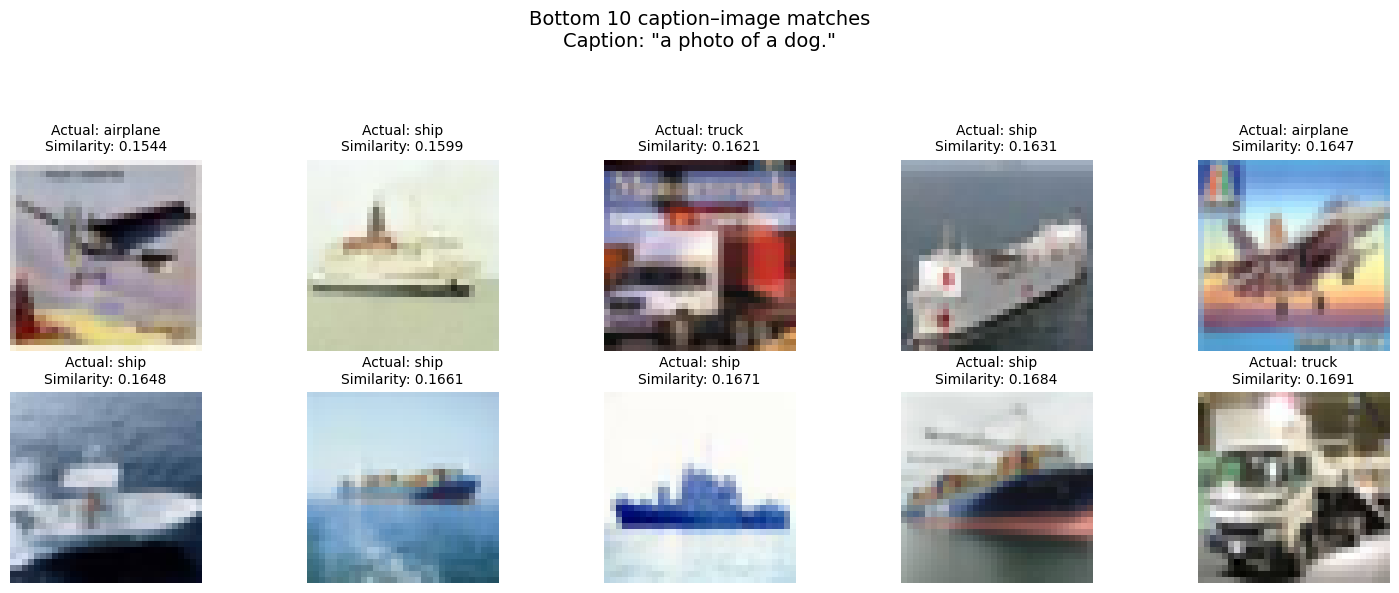

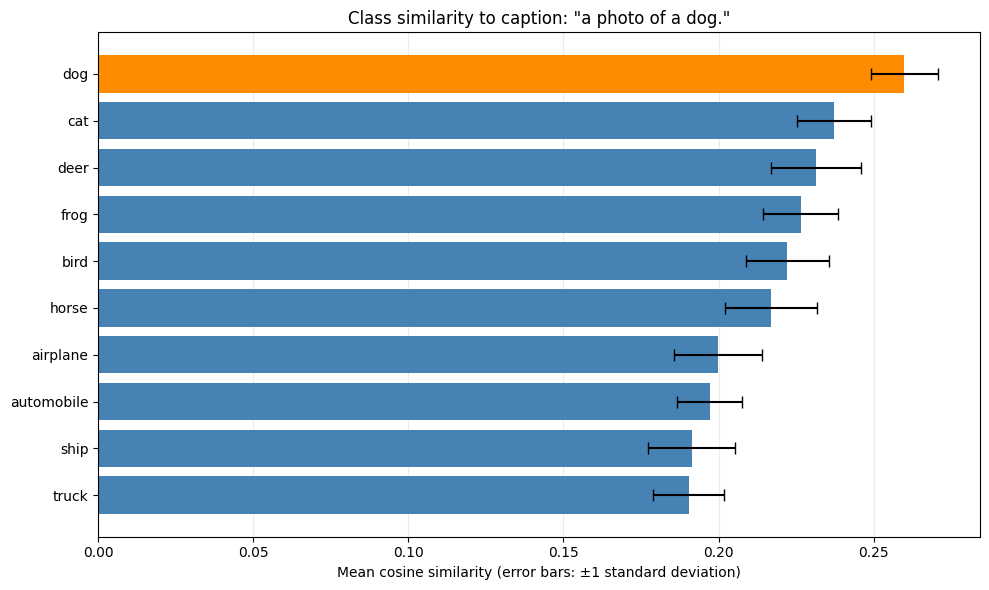

STEP 6 completed successfully.


In [6]:
# ============================================================
# STEP 6: VISUALIZE IMAGES WITH SIMILARITY SCORES
# ============================================================

import matplotlib.pyplot as plt

def show_matches(indices, title):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))

    for ax, idx in zip(axes.flat, indices):
        idx = int(idx)
        ax.imshow(images[idx])
        ax.set_title(
            f"Actual: {class_names[int(labels[idx])]}\n"
            f"Similarity: {similarity_scores[idx]:.4f}",
            fontsize=10
        )
        ax.axis("off")

    fig.suptitle(f'{title}\nCaption: "{caption}"', fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()

# Highest and lowest similarities across all 1,000 images
ranked_indices = np.argsort(similarity_scores)

show_matches(
    ranked_indices[-10:][::-1],
    "Top 10 caption–image matches"
)

show_matches(
    ranked_indices[:10],
    "Bottom 10 caption–image matches"
)

# Compare the mean similarity for all 10 classes
summary = class_similarity_summary.sort_values("mean")

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "darkorange" if name == "dog" else "steelblue"
    for name in summary.index
]

ax.barh(
    summary.index,
    summary["mean"],
    xerr=summary["std"],
    color=colors,
    capsize=4
)

ax.set_xlabel("Mean cosine similarity (error bars: ±1 standard deviation)")
ax.set_title(f'Class similarity to caption: "{caption}"')
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("STEP 6 completed successfully.")

In [7]:
# ============================================================
# STEP 7: ZERO-SHOT CLASSIFICATION WITH CLIP
# ============================================================

# Prompt order must match the dataset's class order
class_prompts = [
    f"a photo of an {name}." if name in ["airplane", "automobile"]
    else f"a photo of a {name}."
    for name in class_names
]

with torch.inference_mode():
    text_tokens = clip.tokenize(class_prompts).to(device)

    class_text_features = model.encode_text(text_tokens).float()
    class_text_features = F.normalize(class_text_features, dim=-1)
    class_text_features = class_text_features.cpu()

    # Reuse the normalized image embeddings from Step 4
    class_similarities = image_features @ class_text_features.T

    # Predict the class with the highest cosine similarity
    predictions = class_similarities.argmax(dim=1).numpy()

# Record predictions
classification_df = pd.DataFrame({
    "Sample index": np.arange(len(images)),
    "CIFAR-10 test index": selected_indices,
    "Actual class": [class_names[int(i)] for i in labels],
    "Predicted class": [class_names[int(i)] for i in predictions],
    "Highest similarity": class_similarities.max(dim=1).values.numpy(),
    "Correct": predictions == labels
})

assert class_similarities.shape == (1000, 10)

print("Class prompts:")
for name, prompt in zip(class_names, class_prompts):
    print(f"  {name}: {prompt}")

print("\nExample predictions:")
display(classification_df.head(10).round(4))

print(
    f"\nOverall accuracy on the 1,000-image subset: "
    f"{100 * (predictions == labels).mean():.2f}%"
)
print("STEP 7 completed successfully.")

Class prompts:
  airplane: a photo of an airplane.
  automobile: a photo of an automobile.
  bird: a photo of a bird.
  cat: a photo of a cat.
  deer: a photo of a deer.
  dog: a photo of a dog.
  frog: a photo of a frog.
  horse: a photo of a horse.
  ship: a photo of a ship.
  truck: a photo of a truck.

Example predictions:


,Sample index,CIFAR-10 test index,Actual class,Predicted class,Highest similarity,Correct
0,0,5422,automobile,automobile,0.2424,True
1,1,2695,bird,bird,0.2799,True
2,2,6270,bird,bird,0.2843,True
3,3,7126,airplane,airplane,0.2457,True
4,4,2851,deer,deer,0.2740,True
5,5,923,truck,automobile,0.2389,False
6,6,4474,airplane,airplane,0.2423,True
7,7,831,cat,cat,0.2528,True
8,8,7294,dog,dog,0.2710,True
9,9,3289,ship,ship,0.2398,True



Overall accuracy on the 1,000-image subset: 88.50%
STEP 7 completed successfully.


Per-class accuracy:


,Class,Total images,Correct,Incorrect,Accuracy (%)
0,airplane,100,92,8,92.0
1,automobile,100,92,8,92.0
2,bird,100,85,15,85.0
3,cat,100,91,9,91.0
4,deer,100,72,28,72.0
5,dog,100,91,9,91.0
6,frog,100,76,24,76.0
7,horse,100,98,2,98.0
8,ship,100,97,3,97.0
9,truck,100,91,9,91.0



Overall accuracy: 88.50%


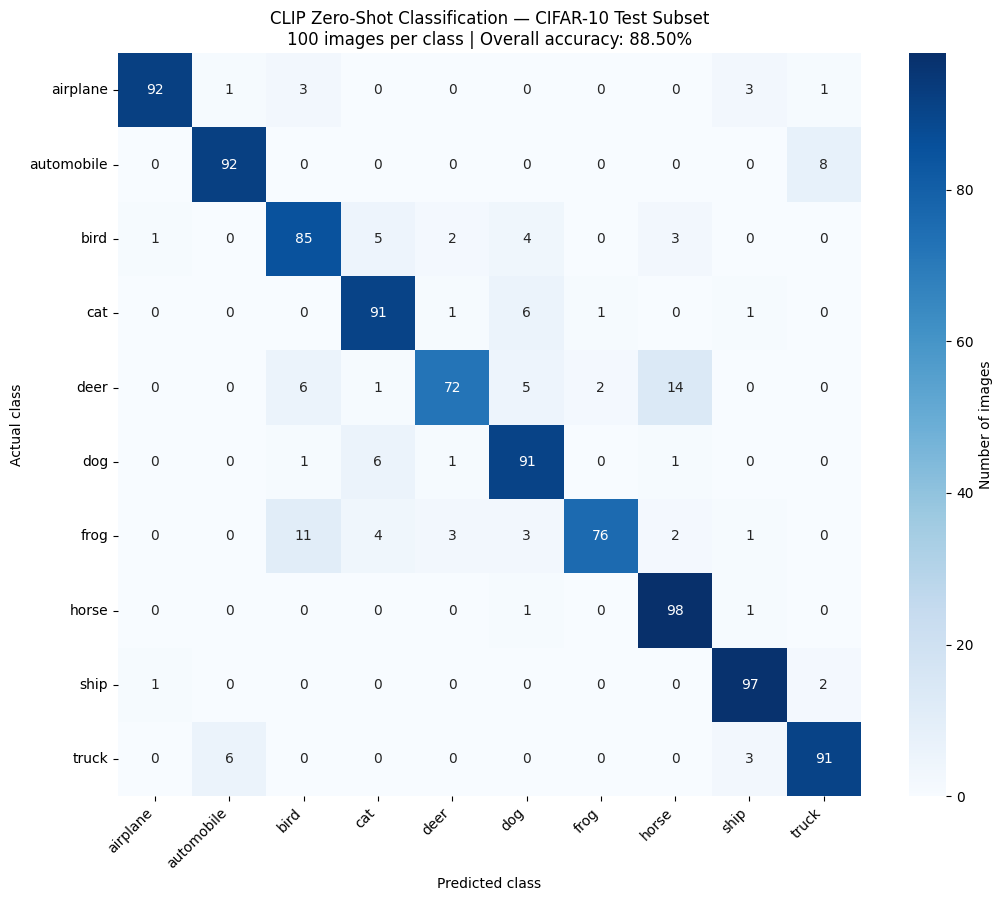


Most frequent class confusions:


,Actual class,Predicted class,Errors
0,deer,horse,14
1,frog,bird,11
2,automobile,truck,8
3,dog,cat,6
4,truck,automobile,6
5,deer,bird,6
6,cat,dog,6
7,bird,cat,5
8,deer,dog,5
9,bird,dog,4



STEP 8 completed successfully.


In [8]:
# ============================================================
# STEP 8: PER-CLASS ACCURACY AND CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Rows = actual classes; columns = predicted classes
cm = confusion_matrix(
    labels,
    predictions,
    labels=np.arange(len(class_names))
)

class_totals = cm.sum(axis=1)
class_correct = cm.diagonal()

per_class_df = pd.DataFrame({
    "Class": class_names,
    "Total images": class_totals,
    "Correct": class_correct,
    "Incorrect": class_totals - class_correct,
    "Accuracy (%)": 100 * class_correct / class_totals
})

print("Per-class accuracy:")
display(per_class_df.round(2))

overall_accuracy = 100 * class_correct.sum() / cm.sum()
print(f"\nOverall accuracy: {overall_accuracy:.2f}%")

# Plot confusion matrix using image counts
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    square=True,
    cbar_kws={"label": "Number of images"}
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(
    "CLIP Zero-Shot Classification — CIFAR-10 Test Subset\n"
    f"100 images per class | Overall accuracy: {overall_accuracy:.2f}%"
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Report the most frequent directional mistakes
confusions = [
    {
        "Actual class": class_names[i],
        "Predicted class": class_names[j],
        "Errors": int(cm[i, j])
    }
    for i in range(len(class_names))
    for j in range(len(class_names))
    if i != j and cm[i, j] > 0
]

print("\nMost frequent class confusions:")
display(
    pd.DataFrame(
        confusions,
        columns=["Actual class", "Predicted class", "Errors"]
    )
    .sort_values("Errors", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

assert cm.sum() == 1000
assert np.all(class_totals == 100)
assert class_correct.sum() == (predictions == labels).sum()

print("\nSTEP 8 completed successfully.")

## STEP 9: DOCUMENT FINDINGS

### Experimental setup
- Model: pretrained OpenAI CLIP ViT-B/32.
- Dataset: balanced subset of the CIFAR-10 test set.
- Sample size: 1,000 images, with 100 images per class.
- Random seed: 42.
- Image preprocessing: CLIP's provided preprocessing function.
- Image and text embeddings were L2-normalized.
- No training or fine-tuning was performed.

### Part 1: Caption–image similarity
The caption was “a photo of a dog.” Cosine similarity was computed
between the caption embedding and each of the 1,000 image embeddings.

Dog images had the highest mean similarity (0.2599), followed by
cats (0.2371) and deer (0.2315). Trucks had the lowest mean similarity
(0.1904). Nine of the ten highest-scoring images were dogs; one was
a cat. This shows that CLIP generally ranked images matching the
caption highly, although some images from other classes also scored
highly.

The notebook displays the ten highest- and ten lowest-scoring images
with their similarity scores, along with class-level mean similarities.
Error bars represent ±1 standard deviation within each class.
Similarity scores are not probabilities.

### Part 2: Zero-shot classification
Each image was compared with ten text prompts, one for each class.
Prompts used “a photo of a [class].”, with “an” for airplane and
automobile. The class with the highest cosine similarity was selected.

CLIP correctly classified 885 of 1,000 images, achieving 88.50%
overall accuracy.

| Class | Correct / Total | Accuracy |
|---|---|---|
| airplane | 92 / 100 | 92% |
| automobile | 92 / 100 | 92% |
| bird | 85 / 100 | 85% |
| cat | 91 / 100 | 91% |
| deer | 72 / 100 | 72% |
| dog | 91 / 100 | 91% |
| frog | 76 / 100 | 76% |
| horse | 98 / 100 | 98% |
| ship | 97 / 100 | 97% |
| truck | 91 / 100 | 91% |

Horse had the highest accuracy (98%), followed by ship (97%).
Deer (72%) and frog (76%) were the most difficult classes.

The most frequent directional errors were deer predicted as horse
(14 images), frog predicted as bird (11 images), and automobile
predicted as truck (8 images). Cats and dogs were confused in both
directions, with six errors each way. Shared visual features may
contribute to some confusions, but the counts alone do not establish
their cause.

The confusion matrix uses actual classes as rows and predicted classes
as columns. Diagonal entries represent correct predictions.

### Limitations
Results describe this fixed 1,000-image subset, not the full CIFAR-10
test set. CIFAR-10 images have a native resolution of 32 × 32 pixels,
which limits available visual detail. Results may change with a
different sample, CLIP model, or text prompt wording.

In [10]:
# ============================================================
# STEP 10: FINAL ASSIGNMENT VERIFICATION
# ============================================================

checks = {
    "100 images from each of 10 classes":
        len(images) == 1000
        and np.all(np.bincount(labels, minlength=10) == 100),

    "Caption defined":
        isinstance(caption, str) and bool(caption.strip()),

    "Image embeddings extracted":
        tuple(image_features.shape) == (1000, 512),

    "Image embeddings normalized":
        torch.allclose(
            image_features.norm(dim=-1),
            torch.ones(1000),
            atol=1e-5
        ),

    "Caption embedding normalized":
        torch.allclose(
            caption_features.norm(dim=-1),
            torch.ones(1),
            atol=1e-5
        ),

    "Similarity scores computed for all images":
        len(similarity_scores) == 1000
        and np.isfinite(similarity_scores).all(),

    "Zero-shot predictions generated":
        len(predictions) == 1000,

    "Per-class accuracy calculated":
        len(per_class_df) == 10,

    "Confusion matrix calculated":
        cm.shape == (10, 10) and cm.sum() == 1000,
}

for requirement, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {requirement}")

assert all(checks.values()), "Resolve failed checks before submitting."

print(f"\nOverall accuracy: {100 * (predictions == labels).mean():.2f}%")
print("\nMANUAL CHECKS:")
print("1. Step 6 image grids and similarity chart are visible.")
print("2. Step 8 confusion matrix is visible.")
print("3. Step 9 findings are included as a Text cell.")
print("\nSTEP 10 completed successfully.")

PASS: 100 images from each of 10 classes
PASS: Caption defined
PASS: Image embeddings extracted
PASS: Image embeddings normalized
PASS: Caption embedding normalized
PASS: Similarity scores computed for all images
PASS: Zero-shot predictions generated
PASS: Per-class accuracy calculated
PASS: Confusion matrix calculated

Overall accuracy: 88.50%

MANUAL CHECKS:
1. Step 6 image grids and similarity chart are visible.
2. Step 8 confusion matrix is visible.
3. Step 9 findings are included as a Text cell.

STEP 10 completed successfully.
